# Porównanie okresów: 2018–2019 vs 2021–2023

Ta sama procedura co w `01_analiza_glowna.ipynb` (średnie per stan → PCA → Ward k=4 / K-Means k=5), uruchomiona osobno dla okresu przed i po pandemii. Pytanie: czy zależności i podział stanów zmieniły się po COVID?

Wersja kursowa była dwiema kopiami notebooka głównego z nazwami klastrów przypisanymi na sztywno do numerów, przez co część etykiet była błędna (np. stany Midwest opisane jako „Południe”). Tutaj nazwy są wyznaczane z profili w każdym okresie.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import adjusted_rand_score

from ushealth.data import CLUSTER_COLS, LABELS, load_panel, state_profile
from ushealth import clustering as cl
from ushealth import plots

plots.setup()
panel = load_panel()
PERIODS = {"2018-2019": (2018, 2019), "2021-2023": (2021, 2023)}

## 1. Zmiany w korelacjach

In [2]:
corrs = {p: state_profile(panel, years=y)[CLUSTER_COLS].corr(method="spearman") for p, y in PERIODS.items()}
diff = (corrs["2021-2023"] - corrs["2018-2019"]).stack()
diff = diff[diff.index.get_level_values(0) < diff.index.get_level_values(1)]
top = diff.abs().sort_values(ascending=False).head(8).index
pd.DataFrame({
    "2018-2019": [corrs["2018-2019"].loc[a, b] for a, b in top],
    "2021-2023": [corrs["2021-2023"].loc[a, b] for a, b in top],
}, index=[f"{LABELS[a]} – {LABELS[b]}" for a, b in top]).round(2)

,2018-2019,2021-2023
bezrobotni % – praca z domu %,-0.32,0.19
bezrobotni % – dojazd autem %,-0.07,-0.41
otyłość % – bezrobotni %,0.10,-0.24
mediana dochodu – praca z domu %,0.40,0.70
bez ubezpieczenia % – praca z domu %,0.01,-0.29
praca z domu % – wyższe wykształcenie %,0.55,0.82
wysoka aktywność % – praca z domu %,0.63,0.35
mediana dochodu – bezrobotni %,-0.04,0.21


## 2. PCA i klasteryzacja w każdym okresie

In [3]:
results = {}
for period, years in PERIODS.items():
    states = state_profile(panel, years=years)
    X_scaled, X_pca, pca = cl.fit_pca(states[CLUSTER_COLS].values)
    X2 = X_pca[:, :2]
    labels = {"Ward k=4": cl.hierarchical(X2, 4), "K-Means k=5": cl.kmeans(X2, 5)}
    results[period] = dict(states=states, X2=X2, pca=pca, labels=labels,
                           names={m: cl.cluster_names(states, lab, CLUSTER_COLS) for m, lab in labels.items()})
    print(f"{period}: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}")
    for m, lab in labels.items():
        print(f"  {m}: silhouette {cl.scores(X2, lab)['silhouette']:.3f}")

2018-2019: PC1 52.0%, PC2 12.7%
  Ward k=4: silhouette 0.429
  K-Means k=5: silhouette 0.497
2021-2023: PC1 53.1%, PC2 16.3%
  Ward k=4: silhouette 0.422
  K-Means k=5: silhouette 0.433


In [4]:
# PC1 loadings by period (sign aligned so that obesity loads positively)
pc1 = {}
for period, r in results.items():
    comp = pd.Series(r["pca"].components_[0], index=[LABELS[c] for c in CLUSTER_COLS])
    pc1[period] = comp * (1 if comp[LABELS["Obesity"]] > 0 else -1)
pd.DataFrame(pc1).round(2).sort_values("2021-2023")

,2018-2019,2021-2023
wyższe wykształcenie %,-0.34,-0.36
mediana dochodu,-0.33,-0.35
praca z domu %,-0.28,-0.31
siłownie / 100k,-0.27,-0.27
wysoka aktywność %,-0.29,-0.26
bezrobotni %,0.12,-0.01
śr. temperatura °C,0.23,0.17
bez ubezpieczenia %,0.19,0.19
dojazd autem %,0.26,0.31
ubóstwo rodzin %,0.35,0.33


In [5]:
for period, r in results.items():
    print(period)
    for name, grp in r["states"].groupby(r["names"]["Ward k=4"]):
        print(f"  {name} ({len(grp)}): {', '.join(grp['LocationAbbr'])}")
for m in ["Ward k=4", "K-Means k=5"]:
    ari = adjusted_rand_score(results["2018-2019"]["labels"][m], results["2021-2023"]["labels"][m])
    print(f"\nZgodność podziałów między okresami ({m}): ARI = {ari:.2f}")

2018-2019
  R1: ubóstwo rodzin ↑, brak aktywności ↑ (7): AL, AR, KY, LA, MS, OK, WV
  R2: bez ubezpieczenia ↑, mediana dochodu ↓ (13): FL, GA, IN, KS, MI, MO, NV, NM, NC, OH, SC, TN, TX
  R3: bezrobotni ↓, śr. temperatura °C ↓ (15): CO, ID, IA, ME, MN, MT, NE, NH, ND, SD, UT, VT, WA, WI, WY
  R4: mediana dochodu ↑, dojazd autem ↓ (15): AK, AZ, CA, CT, DE, HI, IL, MD, MA, NJ, NY, OR, PA, RI, VA
2021-2023
  R1: brak aktywności ↑, ubóstwo rodzin ↑ (7): AL, AR, KY, LA, MS, OK, WV
  R2: bez ubezpieczenia ↑, mediana dochodu ↓ (13): FL, GA, IN, KS, MI, MO, NV, NM, NC, OH, SC, TN, TX
  R3: bezrobotni ↓, śr. temperatura °C ↓ (9): ID, IA, ME, MT, NE, ND, SD, WI, WY
  R4: mediana dochodu ↑, dojazd autem ↓ (21): AK, AZ, CA, CO, CT, DE, HI, IL, MD, MA, MN, NH, NJ, NY, OR, PA, RI, UT, VT, VA, WA

Zgodność podziałów między okresami (Ward k=4): ARI = 0.70

Zgodność podziałów między okresami (K-Means k=5): ARI = 0.64


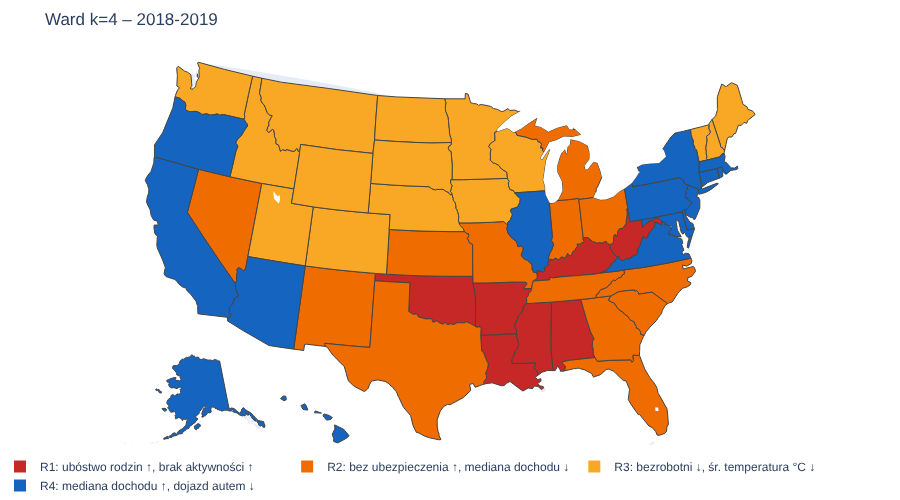

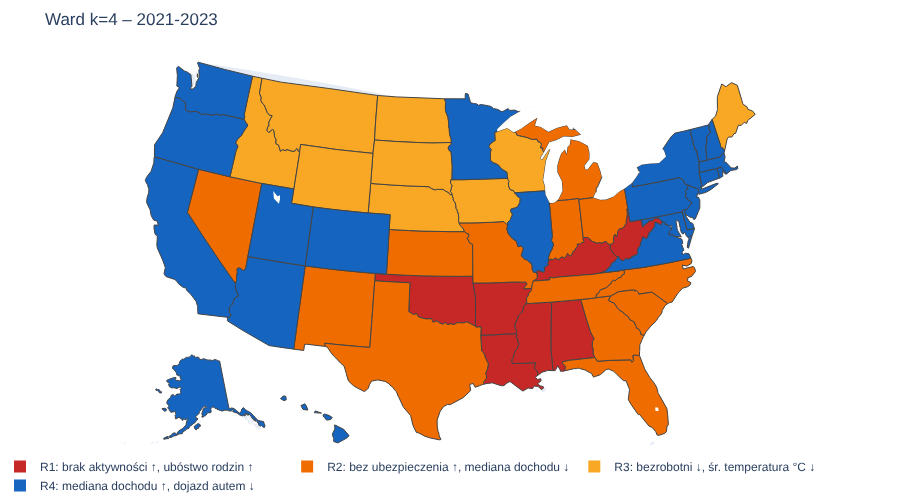

In [6]:
for period, r in results.items():
    fig = plots.cluster_map(r["states"], r["names"]["Ward k=4"], f"Ward k=4 – {period}")
    plots.save(fig, f"period_map_ward_{period}")
    fig.show()

## 3. Wnioski

- **Najmocniej zmieniły się korelacje pracy z domu:** po COVID silniej wiąże się z wykształceniem (ρ 0,55 → 0,82) i dochodem (0,40 → 0,70), a słabiej z wysoką aktywnością fizyczną (0,63 → 0,35). Praca zdalna stała się bardziej cechą zamożnych, wykształconych stanów niż „aktywnego stylu życia”.
- **Główna oś zróżnicowania (PC1) się nie zmieniła:** ładunki są niemal identyczne w obu okresach.
- **Podział stanów jest w dużej mierze stabilny** (ARI 0,70 dla Ward). Rdzeń wysokiego ryzyka (R1) i grupa R2 są identyczne w obu okresach. Zmiana dotyczy północnych stanów: CO, MN, NH, UT, VT i WA przechodzą z grupy „chłodne, niskie bezrobocie” do grupy zamożnej (R4). To spójne ze wzrostem znaczenia pracy zdalnej i dochodu.
- Wersja kursowa raportowała rozpad Południa na dwa klastry po 2021. Po poprawieniu etykiet klastrów i danych o wykształceniu ten efekt nie występuje.